# Bài 5 (Trang 26) – Gom cụm MNIST bằng k-Means và so sánh với nhãn có sẵn

**Họ tên:** Mai Quốc Đại — **MSSV:** 6451071013 — **Lớp:** CQ.64.CNTT

## Đọc và chuẩn hóa dữ liệu MNIST
Mỗi ảnh 28x28 được làm phẳng thành vector 784 chiều, giá trị pixel chia 255.

In [1]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
import numpy as np
import pandas as pd
pd.set_option("display.width", 140)
import matplotlib.pyplot as plt
import seaborn as sns
from keras.datasets import mnist
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             adjusted_rand_score, normalized_mutual_info_score)

(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
X_train = train_images.reshape(len(train_images), -1) / 255.0
X_test = test_images.reshape(len(test_images), -1) / 255.0
print("X_train:", X_train.shape, "- X_test:", X_test.shape)

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
X_train: (60000, 784) - X_test: (10000, 784)


## Gom cụm bằng k-Means (k = 10)

In [2]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
kmeans = KMeans(n_clusters=10, n_init=10, random_state=42)
kmeans.fit(X_train)
clusters_train = kmeans.labels_
print("Số phần tử mỗi cụm:", np.bincount(clusters_train))
print("Inertia:", round(kmeans.inertia_, 2))

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Số phần tử mỗi cụm: [5720 5966 6526 4679 3178 5592 8855 8934 7454 3096]
Inertia: 2352826.63


## Tâm các cụm
Mỗi tâm cụm là một vector 784 chiều, hiển thị lại dưới dạng ảnh 28x28.

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


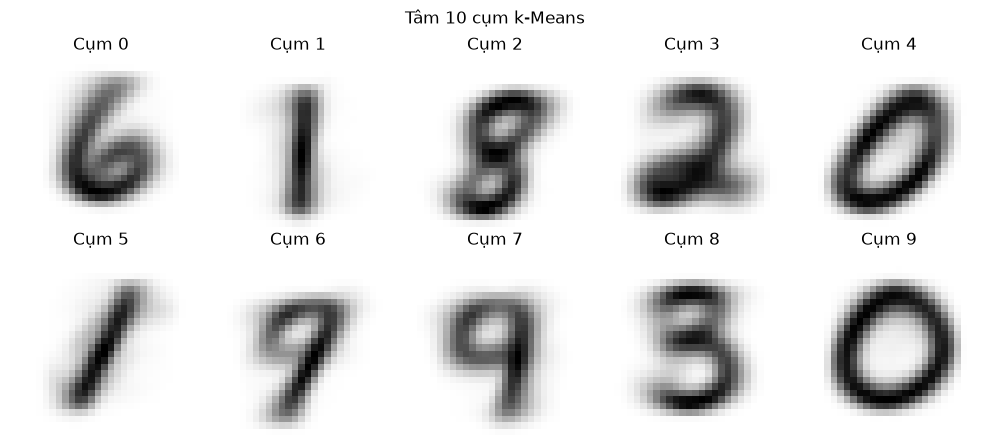

In [3]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
fig, ax = plt.subplots(2, 5, figsize=(10, 4.5))
for i, axi in enumerate(ax.flat):
    axi.imshow(kmeans.cluster_centers_[i].reshape(28, 28), cmap="binary")
    axi.set_title(f"Cụm {i}"); axi.axis("off")
plt.suptitle("Tâm 10 cụm k-Means"); plt.tight_layout(); plt.show()

## Gán nhãn cho cụm
Cụm không có nhãn sẵn, nên mỗi cụm được gán chữ số xuất hiện nhiều nhất trong cụm đó (trên tập train).

In [4]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
cluster_to_label = {}
for c in range(10):
    nhan_trong_cum = train_labels[clusters_train == c]
    cluster_to_label[c] = int(np.bincount(nhan_trong_cum).argmax())
    ty_le = np.mean(nhan_trong_cum == cluster_to_label[c])
    print(f"Cụm {c}: {len(nhan_trong_cum):5d} ảnh -> nhãn {cluster_to_label[c]} (độ thuần khiết {ty_le:.2%})")
print("Các chữ số không được cụm nào đại diện:", sorted(set(range(10)) - set(cluster_to_label.values())))

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Cụm 0:  5720 ảnh -> nhãn 6 (độ thuần khiết 85.89%)
Cụm 1:  5966 ảnh -> nhãn 1 (độ thuần khiết 62.30%)
Cụm 2:  6526 ảnh -> nhãn 8 (độ thuần khiết 52.96%)
Cụm 3:  4679 ảnh -> nhãn 2 (độ thuần khiết 89.61%)
Cụm 4:  3178 ảnh -> nhãn 0 (độ thuần khiết 78.57%)
Cụm 5:  5592 ảnh -> nhãn 1 (độ thuần khiết 53.24%)
Cụm 6:  8855 ảnh -> nhãn 7 (độ thuần khiết 42.61%)
Cụm 7:  8934 ảnh -> nhãn 4 (độ thuần khiết 35.70%)
Cụm 8:  7454 ảnh -> nhãn 3 (độ thuần khiết 52.66%)
Cụm 9:  3096 ảnh -> nhãn 0 (độ thuần khiết 90.70%)
Các chữ số không được cụm nào đại diện: [5, 9]


## So sánh kết quả gom cụm với nhãn có sẵn

In [5]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
y_train_pred = np.array([cluster_to_label[c] for c in clusters_train])
clusters_test = kmeans.predict(X_test)
y_test_pred = np.array([cluster_to_label[c] for c in clusters_test])
print("Accuracy (train):", round(accuracy_score(train_labels, y_train_pred), 4))
print("Accuracy (test) :", round(accuracy_score(test_labels, y_test_pred), 4))
print("Adjusted Rand Index (test):", round(adjusted_rand_score(test_labels, clusters_test), 4))
print("NMI (test):", round(normalized_mutual_info_score(test_labels, clusters_test), 4))
print("\nClassification report (test):")
print(classification_report(test_labels, y_test_pred, digits=4, zero_division=0))

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Accuracy (train): 0.5908
Accuracy (test) : 0.595
Adjusted Rand Index (test): 0.3671
NMI (test): 0.4993

Classification report (test):
              precision    recall  f1-score   support

           0     0.8360    0.8898    0.8621       980
           1     0.6129    0.9947    0.7585      1135
           2     0.8849    0.6851    0.7723      1032
           3     0.5293    0.6891    0.5987      1010
           4     0.3606    0.5692    0.4415       982
           5     0.0000    0.0000    0.0000       892
           6     0.8558    0.8299    0.8426       958
           7     0.4223    0.5866    0.4910      1028
           8     0.5384    0.6047    0.5696       974
           9     0.0000    0.0000    0.0000      1009

    accuracy                         0.5950     10000
   macro avg     0.5040    0.5849    0.5336     10000
weighted avg     0.5095    0.5950    0.5408     10000



Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


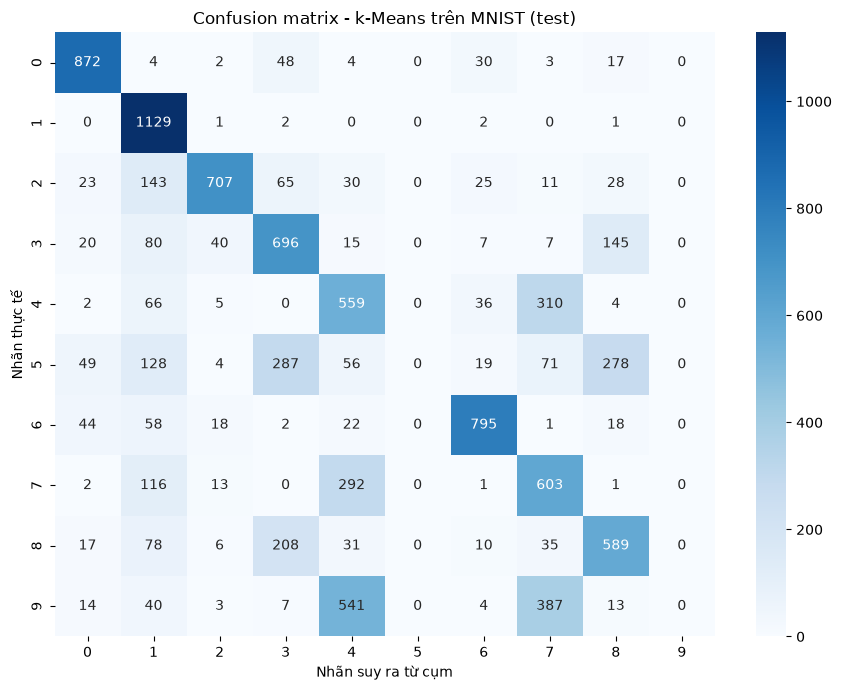

In [6]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
cm = confusion_matrix(test_labels, y_test_pred, labels=range(10))
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Nhãn suy ra từ cụm"); plt.ylabel("Nhãn thực tế")
plt.title("Confusion matrix - k-Means trên MNIST (test)")
plt.tight_layout(); plt.show()

In [7]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
bang = pd.crosstab(pd.Series(clusters_test, name="Cụm"), pd.Series(test_labels, name="Nhãn thực tế"))
print(bang)

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Nhãn thực tế    0    1    2    3    4    5    6    7    8    9
Cụm                                                           
0              30    2   25    7   36   19  795    1   10    4
1               0  660   59   73   30   23   28   59   34   29
2              17    1   28  145    4  278   18    1  589   13
3               2    1  707   40    5    4   18   13    6    3
4             422    0   20   19    1   40   24    1   11   10
5               4  469   84    7   36  105   30   57   44   11
6               3    0   11    7  310   71    1  603   35  387
7               4    0   30   15  559   56   22  292   31  541
8              48    2   65  696    0  287    2    0  208    7
9             450    0    3    1    1    9   20    1    6    4


**Nhận xét:**

- k-Means (k = 10) gom cụm dựa trên khoảng cách Euclid giữa các vector pixel, không dùng nhãn. Sau khi gán mỗi cụm với chữ số chiếm đa số, độ chính xác chỉ khoảng **59%** trên cả train và test (ARI ≈ 0.37, NMI ≈ 0.50), thấp hơn nhiều so với Neural Network có giám sát ở bài trước (~97%).
- Các chữ số có hình dạng đặc trưng như 0, 1, 2, 6 tạo thành cụm khá thuần khiết (độ thuần khiết 78–91%). Ngược lại, 4 – 7 – 9 bị gộp chung vào các cụm 6 và 7, còn 3 – 5 – 8 bị gộp vào cụm 2 và 8.
- Chữ số 1 và 0 mỗi chữ chiếm 2 cụm (do có nhiều kiểu viết: nét thẳng và nét nghiêng), nên không còn cụm nào đại diện cho chữ số 5 và 9, khiến recall của hai lớp này bằng 0.
- Kết luận: k-Means trên pixel thô phản ánh được một phần cấu trúc dữ liệu, nhưng không thay thế được mô hình phân lớp có giám sát.